In this notebook we explore the provided CIL scientific paper dataset.

#### 0.  Load required packages

In [1]:
import pandas as pd
import os
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

#### 1. Load data

In [2]:
DATA_DIR = Path("../data")

RATINGS_PATH = DATA_DIR / "train_ratings.csv"
WISHLIST_PATH = DATA_DIR / "train_tbr.csv"
OUTPUT_FOLDER = "figures"

df_ratings = pd.read_csv(RATINGS_PATH)
df_ratings.head(3)

,sid,pid,rating
0,0,1,5
1,0,13,4
2,0,22,5


In [3]:
df_wishlist = pd.read_csv(WISHLIST_PATH)
df_wishlist.head(3)

,sid,pid
0,0,7
1,0,11
2,0,133


#### 3. Summary statistics

In [4]:
# 1. dimensions
m_scientists = df_ratings["sid"].nunique()
n_papers = df_ratings["pid"].nunique()

# 2. total interactions
n_explicit = len(df_ratings)
n_wishlist = len(df_wishlist)

total_possible = m_scientists * n_papers
rating_density = n_explicit / total_possible
wishlist_density = n_wishlist /total_possible

min_r = df_ratings["rating"].min()
max_r = df_ratings["rating"].max()

print(f"scientists: {m_scientists}")
print(f"papers: {n_papers}")
print(f"explicit ratings: {n_explicit}")
print(f"wishlist entries: {n_wishlist}")
print(f"rating_density: {rating_density:.4f}")
print(f"wishlist_density: {wishlist_density:.4f}")
print(f"rating range: {min_r} - {max_r}")

scientists: 9850
papers: 960
explicit ratings: 1195657
wishlist entries: 345339
rating_density: 0.1264
wishlist_density: 0.0365
rating range: 1 - 5


#### 4. Rating distribution

Figure saved to: figures/A1_rating_distribution.png


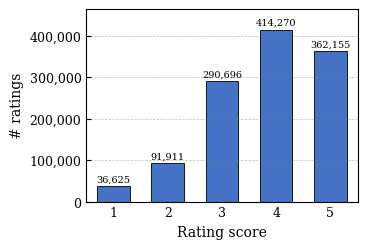

In [5]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib import rcParams

rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["Times New Roman", "DejaVu Serif"],
    "font.size":        10,
    "axes.titlesize":   10,
    "axes.labelsize":   10,
    "xtick.labelsize":  9,
    "ytick.labelsize":  9,
    "axes.linewidth":   0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.direction":  "in",
    "ytick.direction":  "in",
    "pdf.fonttype":     42,   
    "ps.fonttype":      42,
})

rating_counts = df_ratings["rating"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(3.5, 2.5)) 
bars = ax.bar(
    rating_counts.index,
    rating_counts.values,
    color="#4472C4",
    edgecolor="black",
    linewidth=0.6,
    width=0.6,
)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + max(rating_counts.values) * 0.015,
        f"{int(height):,}",
        ha="center", va="bottom", fontsize=7,
    )

ax.set_xlabel("Rating score")
ax.set_ylabel("# ratings")
ax.set_xticks(rating_counts.index)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

ax.tick_params(top=False, right=False, bottom=False, which="both")

ax.yaxis.grid(True, linestyle="--", linewidth=0.5, color="gray", alpha=0.5)

ax.set_xlim(rating_counts.index.min() - 0.5, rating_counts.index.max() + 0.5)
ax.set_ylim(0, max(rating_counts.values) * 1.12)

# Save figure
filename = "A1_rating_distribution.png" 
filepath = os.path.join(OUTPUT_FOLDER, filename)
if not os.path.exists(OUTPUT_FOLDER):
    os.makedirs(OUTPUT_FOLDER)
plt.savefig(filepath, bbox_inches="tight", dpi=300)
print(f"Figure saved to: {filepath}")

plt.show()